# Superstore Sales Profitability Analysis: Project Report

**Domain:** Retail and Sales Analytics (Multi-Market, Multi-Category)

## Project Overview

This project examines order-line records from a superstore business for 1 January 2011 to 31 December 2014. The dataset contains 51,290 records and 27 columns. After one zero-sales row was removed, 51,289 records were analysed.

Sales volume alone does not show whether the business is healthy. This project measures how much profit each part of the business generates, where losses come from, and whether discounting is linked to those losses.

## Business Problem

Sales managers need to know which sub-categories, markets, and customer segments make money and which lose it. High sales in some markets do not show whether the business is healthy. This analysis asks whether discounting is a major cause of losses, and where in the business the losses are concentrated, so that discount and pricing decisions can be based on evidence.

## Project Objectives and Status

1. **Sales, profit, and margin by sub-category and market.** 
2. **Share of loss-making lines at each discount level, and the lowest discount where more than half of lines lose money.**
3. **Margin by segment and ship mode.**
## Business Value & Use Case

- **Sales and pricing managers** can use the discount analysis to set a discount cap and approval rule.
- **Category managers** can review pricing for sub-categories with losses.
- **Regional leads** can compare markets on profit, not only sales.
- **Finance teams** can use the margin figures to prioritise cost reviews in loss-making areas.

## Dataset Information

- **Source:** [Add the original source URL and attribution before submission]
- **File:** `data/superstore_data.csv`
- **Format:** CSV, UTF-8 encoded
- **Size:** 51,290 rows × 27 columns (51,289 after removing one zero-sales row)
- **Time period:** Order dates from 1 January 2011 to 31 December 2014
- **One record represents:** one order line, identified by `Row.ID`. `Order.ID` may appear on more than one row.

**Key fields**

| Field | Meaning |
|---|---|
| Order.Date, Ship.Date | Dates the order was placed and shipped (converted to datetime) |
| Category, Sub.Category, Product.Name | What was sold |
| Sales, Quantity, Discount | Revenue, units, and discount applied |
| Profit, Shipping.Cost | Profit on the line and shipping cost |
| Segment, Customer.ID | Customer type and identifier |
| Market, Region, Country, State, City | Where the order was made |
| Ship.Mode, Order.Priority | Shipping method and priority |

## Method

**Cleaning:**
- Checked for duplicate rows (none) and missing values (none).
- Removed the columns `记录数` (no analytical use), `Market2` (duplicates `Market`), and `weeknum` (derivable from the year).
- Converted order and ship dates to datetime, and sales and profit to float.
- Removed one row with zero sales.

**Features created:** `profit_status`, `ship_days`, `unit_price`, `quarter`, `market_region` (market and region combined), and `profit_margin`.

**Grouping rule:** Region names repeat across markets (for example, "Central" appears in EU, LATAM, and US). All region results use market and region together.

**Margin definition:** Total profit ÷ total sales. Row-level margins are not averaged.

**Tools:** Python 3, Pandas, NumPy, Matplotlib, Seaborn, Plotly, Jupyter Notebook.
## Scope & Limitations

**In scope:**
- Descriptive analysis of order-line sales, profit, discount, and margin, 1 January 2011 to 31 December 2014.
- Sales, profit, and margin by sub-category and market.
- Share of loss-making order lines at each discount level.
- Margin by customer segment and ship mode.

**Not covered in this submission:**
- Year-by-year sales, profit, and margin, and the market with the largest year-on-year change in margin (Objective 4).
- Forecasting, customer churn, and costs not in the dataset (overheads, staff, rent).

**Limitations:**
- The dataset has no cost detail, so profit is before overheads.
- The analysis is descriptive. Discounts and losses occur together, but the data does not show that discounts cause the losses.
- The discount threshold is based on discount levels with at least 30 order lines. Levels with fewer lines were excluded, because their loss share can be misleading.
- Counts of orders use unique order IDs where stated. Other counts are order lines.
- Average discount is an unweighted mean across order lines.
- One row with zero sales was removed.
- No negative sales values appear, so returns are assumed to be unrecorded.

**Assumptions:** Profit values are correct as recorded, and the dataset is complete for the period.
**Assumptions:** Profit values are correct as recorded, and the dataset is complete for the period.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df=pd.read_csv("D:\Capstone_project\superstore_data.csv")

In [2]:
print("Dataset Loaded ")
print("Number of rows and columns:",df.shape)
df.head(5)

Dataset Loaded 
Number of rows and columns: (51290, 27)


,Category,City,Country,Customer.ID,Customer.Name,Discount,Market,记录数,Order.Date,Order.ID,...,Sales,Segment,Ship.Date,Ship.Mode,Shipping.Cost,State,Sub.Category,Year,Market2,weeknum
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,2011-01-07 00:00:00.000,CA-2011-130813,...,19,Consumer,2011-01-09 00:00:00.000,Second Class,4.37,California,Paper,2011,North America,2
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,2011-01-21 00:00:00.000,CA-2011-148614,...,19,Consumer,2011-01-26 00:00:00.000,Standard Class,0.94,California,Paper,2011,North America,4
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05 00:00:00.000,CA-2011-118962,...,21,Consumer,2011-08-09 00:00:00.000,Standard Class,1.81,California,Paper,2011,North America,32
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-05 00:00:00.000,CA-2011-118962,...,111,Consumer,2011-08-09 00:00:00.000,Standard Class,4.59,California,Paper,2011,North America,32
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,2011-09-29 00:00:00.000,CA-2011-146969,...,6,Consumer,2011-10-03 00:00:00.000,Standard Class,1.32,California,Paper,2011,North America,40


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 27 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Category        51290 non-null  str    
 1   City            51290 non-null  str    
 2   Country         51290 non-null  str    
 3   Customer.ID     51290 non-null  str    
 4   Customer.Name   51290 non-null  str    
 5   Discount        51290 non-null  float64
 6   Market          51290 non-null  str    
 7   记录数             51290 non-null  int64  
 8   Order.Date      51290 non-null  str    
 9   Order.ID        51290 non-null  str    
 10  Order.Priority  51290 non-null  str    
 11  Product.ID      51290 non-null  str    
 12  Product.Name    51290 non-null  str    
 13  Profit          51290 non-null  float64
 14  Quantity        51290 non-null  int64  
 15  Region          51290 non-null  str    
 16  Row.ID          51290 non-null  int64  
 17  Sales           51290 non-null  int64  
 1

In [4]:
df.dtypes

Category              str
City                  str
Country               str
Customer.ID           str
Customer.Name         str
Discount          float64
Market                str
记录数                 int64
Order.Date            str
Order.ID              str
Order.Priority        str
Product.ID            str
Product.Name          str
Profit            float64
Quantity            int64
Region                str
Row.ID              int64
Sales               int64
Segment               str
Ship.Date             str
Ship.Mode             str
Shipping.Cost     float64
State                 str
Sub.Category          str
Year                int64
Market2               str
weeknum             int64
dtype: object

In [5]:
df.columns

Index(['Category', 'City', 'Country', 'Customer.ID', 'Customer.Name',
       'Discount', 'Market', '记录数', 'Order.Date', 'Order.ID', 'Order.Priority',
       'Product.ID', 'Product.Name', 'Profit', 'Quantity', 'Region', 'Row.ID',
       'Sales', 'Segment', 'Ship.Date', 'Ship.Mode', 'Shipping.Cost', 'State',
       'Sub.Category', 'Year', 'Market2', 'weeknum'],
      dtype='str')

## Initial Dataset Observations
The file loaded cleanly with 51,290 rows and 27 columns, and it contains no missing values and no duplicate rows. Order dates run from 1 January 2011 to 31 December 2014, and every ship date falls on or after its order date. Discounts range from 0% to 85%, and 12,544 order lines (about 24.5%) show negative profit. Sales are never negative, although one row has a sales value of zero.

At this stage, I have only completed an initial inspection of the dataset. A closer examination of the data types, missing or unknown values, and distributions of important variables will be carried out during the next stages of the projec


# Data cleaning

In [6]:
df.duplicated().sum()

np.int64(0)

**zero duplicated values**

In [7]:
df.isnull().sum()

Category          0
City              0
Country           0
Customer.ID       0
Customer.Name     0
Discount          0
Market            0
记录数               0
Order.Date        0
Order.ID          0
Order.Priority    0
Product.ID        0
Product.Name      0
Profit            0
Quantity          0
Region            0
Row.ID            0
Sales             0
Segment           0
Ship.Date         0
Ship.Mode         0
Shipping.Cost     0
State             0
Sub.Category      0
Year              0
Market2           0
weeknum           0
dtype: int64

**zero null values**

In [8]:
df=df.drop(columns=["记录数"])

In [9]:
df=df.drop(columns=["Market2"])

In [10]:
df=df.drop(columns="weeknum")

In [11]:
df.columns=df.columns.str.lower().str.replace(".","_")

**Changed the column title to lower alphabets and replaced "." with "_"**

**Dropped columns<br>
"记录数" as of irrelevant data,<br>
"Market2" for it shows same as market the difference is the usa and canada are merged as north america,<br>
"weeknum" because it is fully derivable from year**

In [12]:
df["order_date"] = pd.to_datetime(df["order_date"]).dt.normalize()
df["ship_date"] = pd.to_datetime(df["ship_date"]).dt.normalize()

In [13]:
df["sales"] = df["sales"].astype(float).round(2)

In [14]:
df["profit"] = df["profit"].astype(float).round(2)

**Changed data types of "order_date" and "ship_date" to datetime, "sales" and "profit" to float dtype**

In [15]:
df["profit_status"]=np.select(
    [df["profit"]<0,df["profit"]>0],
    ["loss","profit"],
    default="break-even"
)

**Created a new column showing the the row is profit or loss or break even**

In [16]:
df["row_id"].nunique()

51290

In [17]:
df["ship_days"]=(df["ship_date"]-df["order_date"]).dt.days
assert (df["ship_days"]>=0).all(),"Ship date before order date"

df["unit_price"]=(df["sales"]/df["quantity"]).round(2)
assert(df["quantity"]>0).all(),"Zero or negative quantity found"

df["quarter"]=pd.to_datetime(df["order_date"]).dt.quarter

**Created a new columns <br>
"ship_days" showing the total days for the shipment<br>
"unit_price" showing price per unit by sales/quantity<br>
"quarter" shows which quarter of the year is it on<br>**

In [18]:
df.head(2)

,category,city,country,customer_id,customer_name,discount,market,order_date,order_id,order_priority,...,ship_date,ship_mode,shipping_cost,state,sub_category,year,profit_status,ship_days,unit_price,quarter
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,2011-01-07,CA-2011-130813,High,...,2011-01-09,Second Class,4.37,California,Paper,2011,profit,2,6.33,1
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,2011-01-21,CA-2011-148614,Medium,...,2011-01-26,Standard Class,0.94,California,Paper,2011,profit,5,9.50,1


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 28 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   category        51290 non-null  str           
 1   city            51290 non-null  str           
 2   country         51290 non-null  str           
 3   customer_id     51290 non-null  str           
 4   customer_name   51290 non-null  str           
 5   discount        51290 non-null  float64       
 6   market          51290 non-null  str           
 7   order_date      51290 non-null  datetime64[us]
 8   order_id        51290 non-null  str           
 9   order_priority  51290 non-null  str           
 10  product_id      51290 non-null  str           
 11  product_name    51290 non-null  str           
 12  profit          51290 non-null  float64       
 13  quantity        51290 non-null  int64         
 14  region          51290 non-null  str           
 15  row_id       

In [20]:
print(df.columns.tolist())

['category', 'city', 'country', 'customer_id', 'customer_name', 'discount', 'market', 'order_date', 'order_id', 'order_priority', 'product_id', 'product_name', 'profit', 'quantity', 'region', 'row_id', 'sales', 'segment', 'ship_date', 'ship_mode', 'shipping_cost', 'state', 'sub_category', 'year', 'profit_status', 'ship_days', 'unit_price', 'quarter']


In [21]:
df.loc[df["sales"]==0]

,category,city,country,customer_id,customer_name,discount,market,order_date,order_id,order_priority,...,ship_date,ship_mode,shipping_cost,state,sub_category,year,profit_status,ship_days,unit_price,quarter
46158,Office Supplies,Houston,United States,ZC-219104,Zuschuss Carroll,0.8,US,2014-06-20,US-2014-102288,Medium,...,2014-06-24,Standard Class,0.01,Texas,Appliances,2014,loss,4,0.0,2


In [22]:
print(df.loc[46158])

category                                            Office Supplies
city                                                        Houston
country                                               United States
customer_id                                               ZC-219104
customer_name                                      Zuschuss Carroll
discount                                                        0.8
market                                                           US
order_date                                      2014-06-20 00:00:00
order_id                                             US-2014-102288
order_priority                                               Medium
product_id                                          OFF-AP-10002906
product_name      Hoover Replacement Belt for Commercial Guardsm...
profit                                                        -1.11
quantity                                                          1
region                                          

In [23]:
df= df.drop(index=46158)

**Understood row number 46158 is the single cell having 0 sales so dropping it**

In [24]:
df["market_region"] = df["market"] + " | " + df["region"]
df["market_region"].value_counts()

market_region
EU | Central             5822
EMEA | EMEA              5029
Africa | Africa          4587
APAC | Oceania           3487
US | West                3203
APAC | Southeast Asia    3129
LATAM | South            2988
LATAM | Central          2972
US | East                2848
LATAM | North            2644
APAC | North Asia        2338
US | Central             2322
EU | North               2141
APAC | Central Asia      2048
EU | South               2037
LATAM | Caribbean        1690
US | South               1620
Canada | Canada           384
Name: count, dtype: int64

In [25]:
df["discount"] = df["discount"].round(2)

In [26]:
df["profit_margin"] =(df["profit"] / df["sales"].replace(0, pd.NA)).round(2)

In [27]:
df=df[["customer_id","customer_name","city","country","region","market","market_region","category",
       "sub_category","quantity","unit_price","discount","profit","profit_margin","sales",
       "order_date","quarter","year",
       "order_id","product_id", "product_name","ship_date",
       "row_id", "segment","order_priority", "shipping_cost",
       "state", "profit_status","ship_mode","ship_days"]]

In [28]:
df.head(5)

,customer_id,customer_name,city,country,region,market,market_region,category,sub_category,quantity,...,product_name,ship_date,row_id,segment,order_priority,shipping_cost,state,profit_status,ship_mode,ship_days
0,LS-172304,Lycoris Saunders,Los Angeles,United States,West,US,US | West,Office Supplies,Paper,3,...,Xerox 225,2011-01-09,36624,Consumer,High,4.37,California,profit,Second Class,2
1,MV-174854,Mark Van Huff,Los Angeles,United States,West,US,US | West,Office Supplies,Paper,2,...,"Wirebound Service Call Books, 5 1/2"" x 4""",2011-01-26,37033,Consumer,Medium,0.94,California,profit,Standard Class,5
2,CS-121304,Chad Sievert,Los Angeles,United States,West,US,US | West,Office Supplies,Paper,3,...,"Adams Phone Message Book, Professional, 400 Me...",2011-08-09,31468,Consumer,Medium,1.81,California,profit,Standard Class,4
3,CS-121304,Chad Sievert,Los Angeles,United States,West,US,US | West,Office Supplies,Paper,2,...,Xerox 1913,2011-08-09,31469,Consumer,Medium,4.59,California,profit,Standard Class,4
4,AP-109154,Arthur Prichep,Los Angeles,United States,West,US,US | West,Office Supplies,Paper,1,...,Xerox 223,2011-10-03,32440,Consumer,High,1.32,California,profit,Standard Class,4


In [29]:
print(df.columns.tolist())

['customer_id', 'customer_name', 'city', 'country', 'region', 'market', 'market_region', 'category', 'sub_category', 'quantity', 'unit_price', 'discount', 'profit', 'profit_margin', 'sales', 'order_date', 'quarter', 'year', 'order_id', 'product_id', 'product_name', 'ship_date', 'row_id', 'segment', 'order_priority', 'shipping_cost', 'state', 'profit_status', 'ship_mode', 'ship_days']


# Analysis

# Univariate

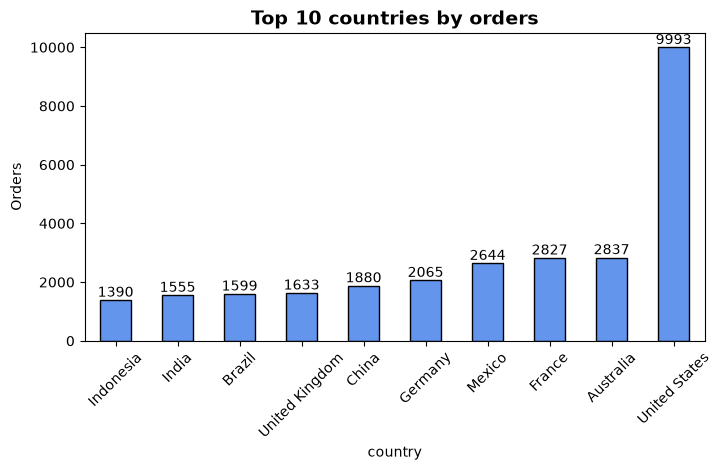

In [30]:
#Top countries by orders

ax=df["country"].value_counts().head(10).sort_values().plot(kind="bar",figsize=(8,4),color="cornflowerblue",edgecolor="black")
ax.bar_label(ax.containers[0])
plt.title("Top 10 countries by orders",fontsize=14,fontweight="bold")
plt.ylabel("Orders")
plt.xticks(rotation=45)
plt.show()

### Shows **USA** have the highest **orders** from whole data

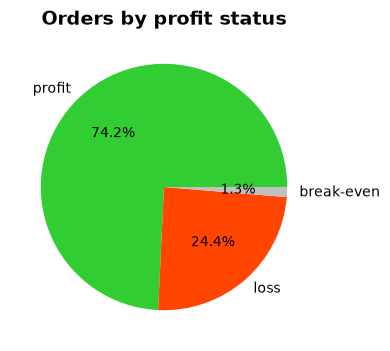

In [31]:
#Profit status

df["profit_status"].value_counts().plot(kind="pie",figsize=(10,4),autopct="%1.1f%%", colors=["limegreen", "orangered", "silver"])
plt.title("Orders by profit status",fontsize=14,fontweight="bold")
plt.show()

### Quarter of orders are in loss and **1.3%**  are in breakeven 

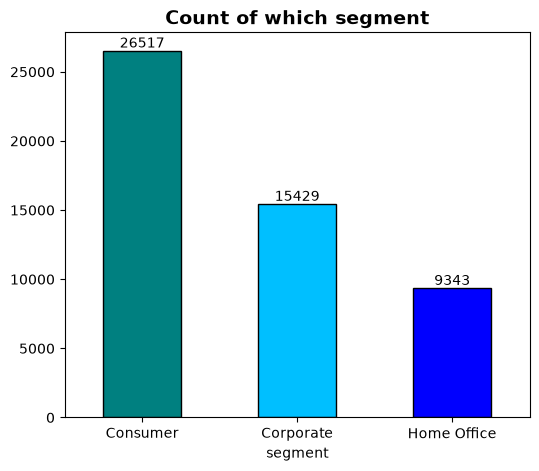

In [32]:
ax=df["segment"].value_counts().plot(kind="bar",color=["teal","deepskyblue","blue"],edgecolor="black",figsize=(6,5))
ax.bar_label(ax.containers[0])
plt.title("Count of which segment",fontsize=14,fontweight="bold")
plt.xticks(rotation=0)
plt.show()

### **Consumers** are the highest among 3, more than **3x** **home office** buyers

In [33]:
#Top 5 loss over countries

top_loss=df.groupby("country")["profit"].sum().sort_values(ascending=True).head(5)
top_loss

country
Turkey        -98447.28
Nigeria       -80750.88
Netherlands   -41070.12
Honduras      -29482.32
Pakistan      -22446.63
Name: profit, dtype: float64

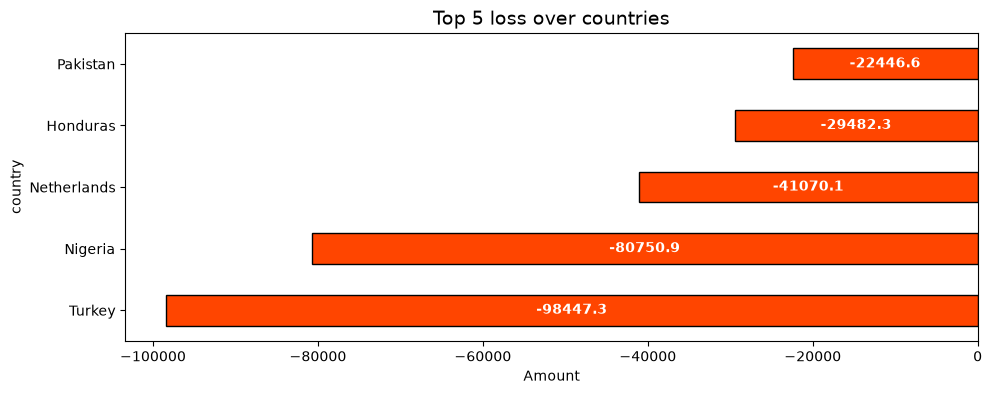

In [34]:
ax=top_loss.plot(kind="barh",figsize=(11,4),color=["orangered"],edgecolor="black")
ax.bar_label(ax.containers[0],label_type="center",fontweight="bold",color="white")
plt.title("Top 5 loss over countries",fontsize=14,)
plt.xlabel("Amount")
plt.xticks(rotation=0)
plt.show()

### Top 3 countries which have Loss are Turkey, Nigeria & Netherlands

# Bivariate

In [35]:
#Sales and Profit of top 5 countries

top=df.groupby("country")[["sales","profit"]].sum().sort_values("sales",ascending=False).head(5)
top

,sales,profit
country,,
United States,2297354.0,286397.65
Australia,925257.0,103907.20
France,858930.0,109028.99
China,700591.0,150683.08
Germany,628857.0,107322.77


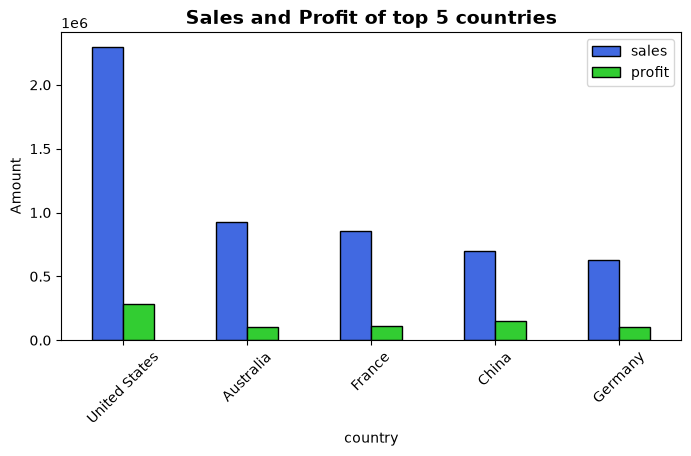

In [36]:
#Sales and Profit of top 5 countries

top.plot(kind="bar", figsize=(8,4),color=["royalblue","limegreen"],edgecolor="black")
plt.title("Sales and Profit of top 5 countries",fontsize=14,fontweight="bold")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.show()

### We found **USA** have the highest Sales and Profit

In [37]:
top_city=df.groupby("city")[["sales","profit"]].sum().sort_values("sales",ascending=False).head(5)
top_city

,sales,profit
city,,
New York City,256397.0,62036.93
Los Angeles,175857.0,30440.77
Manila,120896.0,-11158.54
Seattle,119552.0,29156.08
San Francisco,112690.0,17507.32


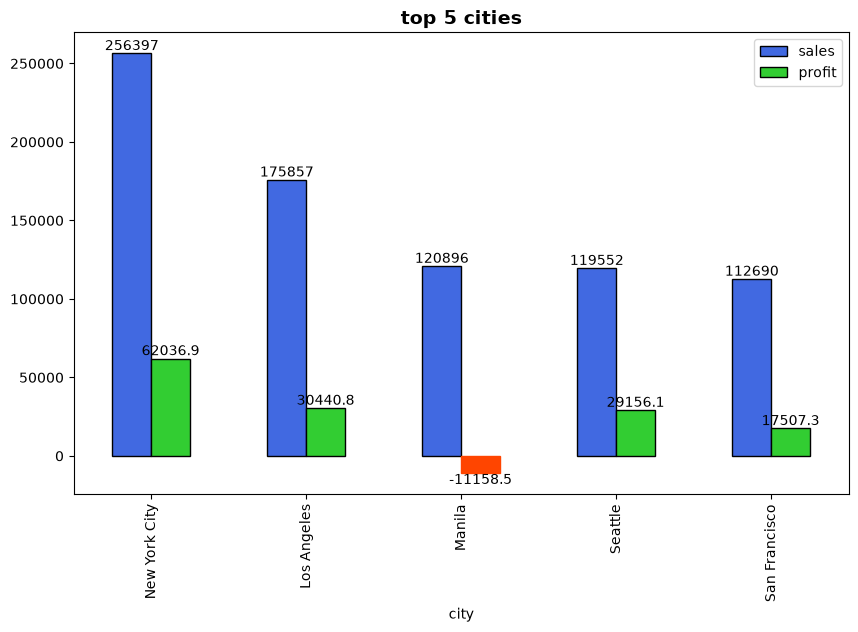

In [38]:
top_city = df.groupby("city")[["sales", "profit"]].sum().sort_values("sales", ascending=False).head(5)
ax = top_city.plot(kind="bar", edgecolor="black",color=["royalblue","limegreen"],figsize=(10,6))
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
for bar in ax.containers[1]:
    if bar.get_height()<0:
        bar.set_color("orangered")
plt.title("top 5 cities",fontsize=14,fontweight="bold")
plt.show()

## In top 5 cities 4 of them are from USA having top sales


In [39]:
#Count of regions overall

region_pie=df.groupby(["market","region"])["country"].nunique().sort_values(ascending=False)
region_pie

market  region        
Africa  Africa            45
EMEA    EMEA              40
LATAM   South             10
APAC    Southeast Asia     8
LATAM   Caribbean          8
APAC    Central Asia       6
        North Asia         6
EU      Central            6
        North              6
LATAM   Central            5
APAC    Oceania            3
EU      South              3
Canada  Canada             1
LATAM   North              1
US      Central            1
        East               1
        South              1
        West               1
Name: country, dtype: int64

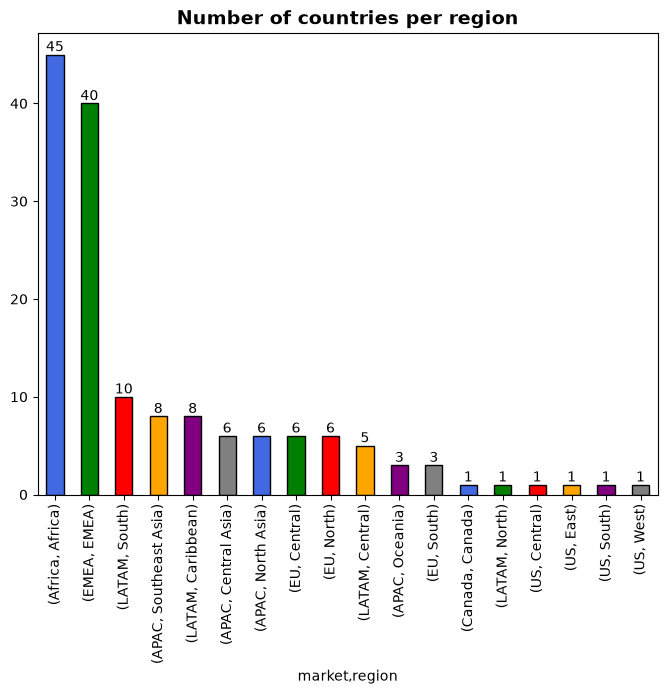

In [57]:
ax=region_pie.plot(kind="bar",figsize=(8,6),color=["royalblue","Green", "Red", "Orange", "Purple","Grey"],edgecolor=("black"))
ax.bar_label(ax.containers[0])
plt.title("Number of countries per region",fontsize=14,fontweight="bold")
plt.show()

### **African** region consists of *highest* country counts

### 

# Multivariate

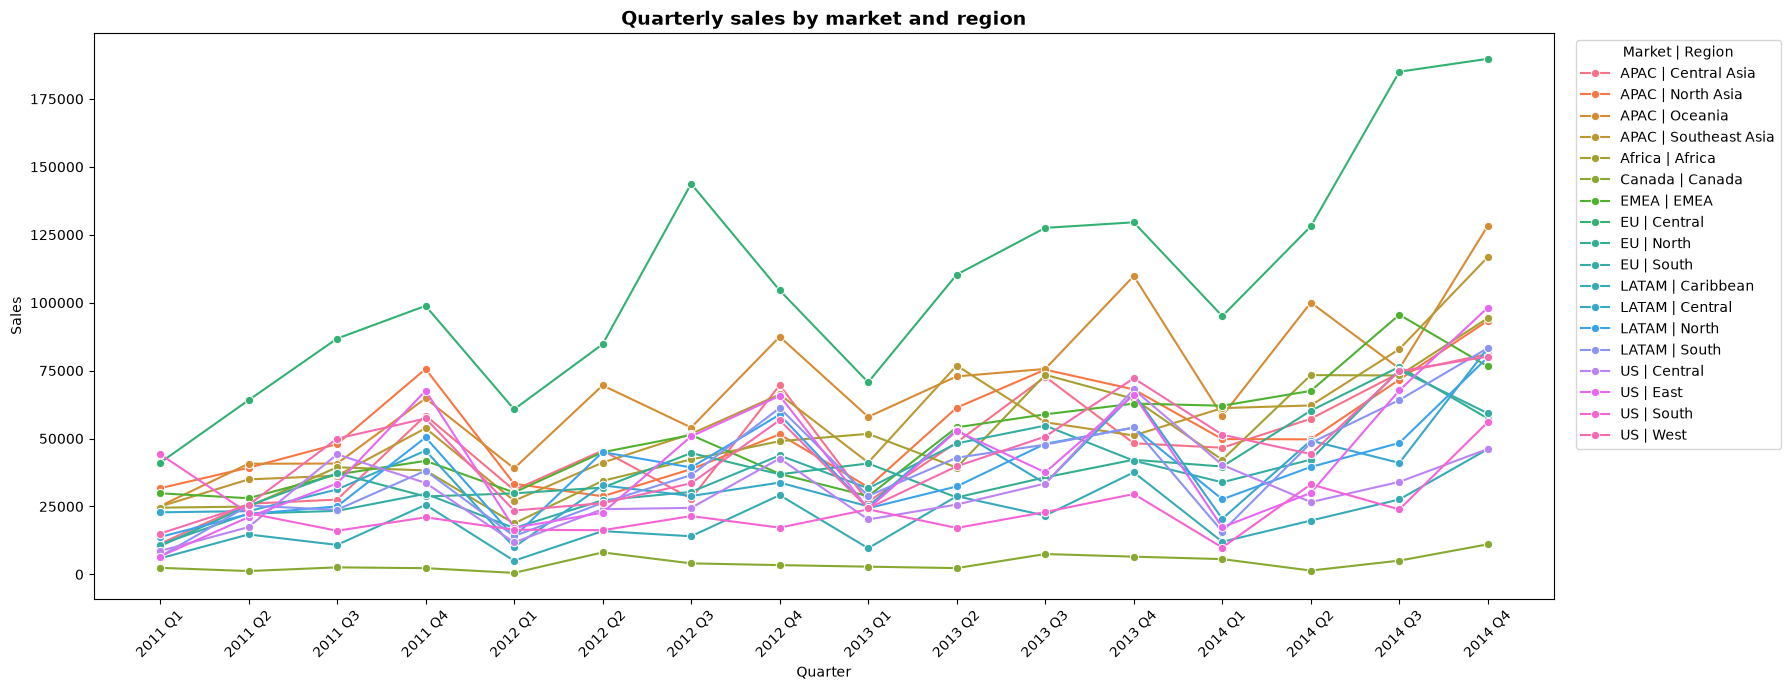

In [41]:
reg_q = df.groupby(["year", "quarter", "market_region"])["sales"].sum().reset_index()
reg_q["period"] = reg_q["year"].astype(str) + " Q" + reg_q["quarter"].astype(str)

plt.figure(figsize=(18, 7))
sns.lineplot(data=reg_q, x="period", y="sales", hue="market_region", marker="o")
plt.title("Quarterly sales by market and region", fontsize=14, fontweight="bold")
plt.xlabel("Quarter")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.legend(title="Market | Region", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

Inside region based analysis **EU CENTRAL** regions quarterly sales the highest

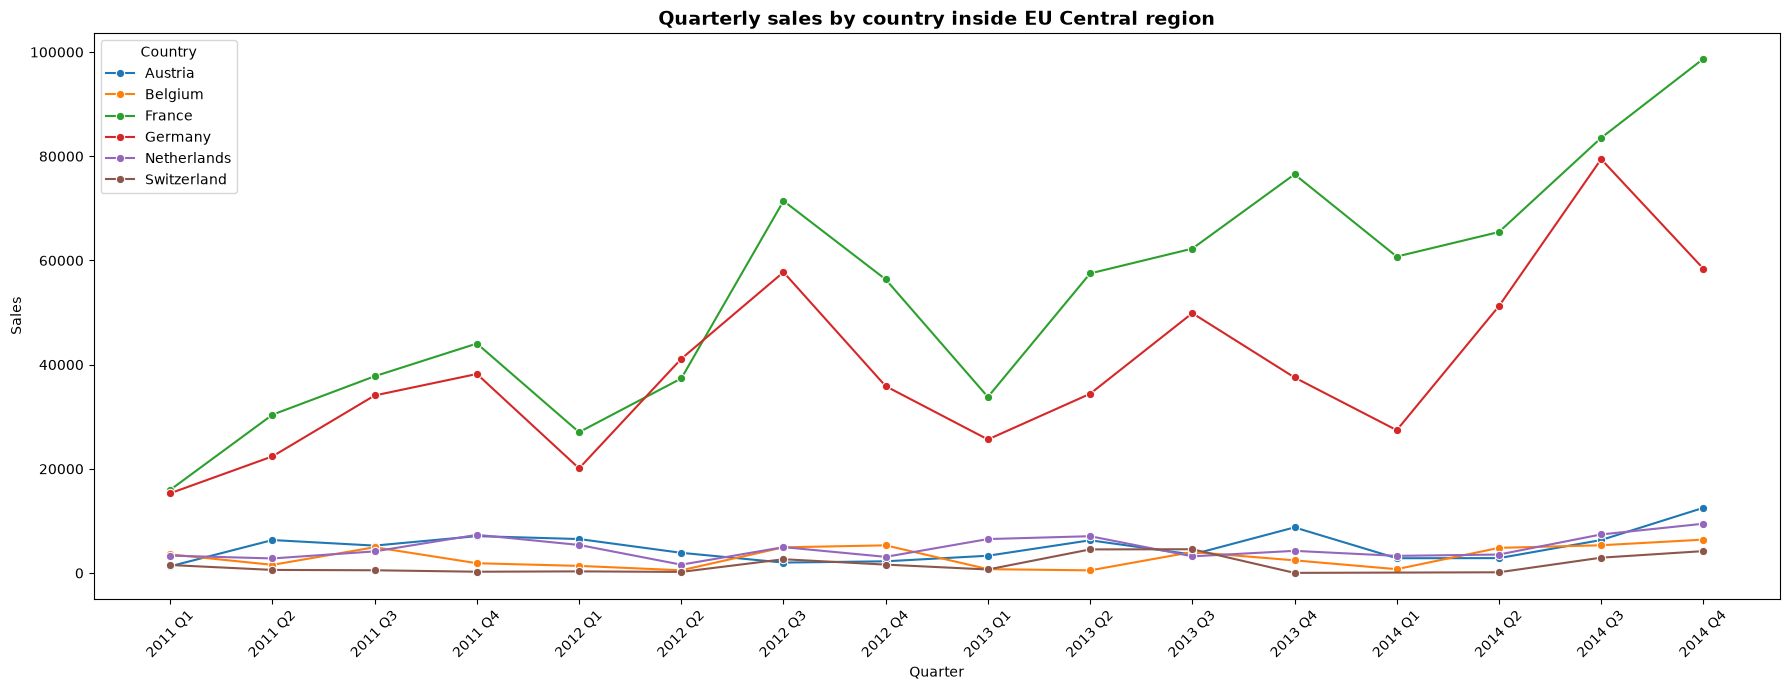

In [42]:
central_country = (df[df["market_region"] == "EU | Central"]
                   .groupby(["year", "quarter", "country"])["sales"].sum().reset_index())
central_country["period"] = central_country["year"].astype(str) + " Q" + central_country["quarter"].astype(str)

plt.figure(figsize=(18, 7))
sns.lineplot(data=central_country, x="period", y="sales", hue="country", marker="o")
plt.title("Quarterly sales by country inside EU Central region", fontsize=14, fontweight="bold")
plt.xlabel("Quarter")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.legend(title="Country", loc="upper left")
plt.tight_layout()
plt.show()

Inside Central region **FRANCE** is the best performing country

In [43]:
best_country_q = (
    df.groupby(["year", "quarter","country","market_region"])["sales"].sum()
    .reset_index()
    .sort_values(["year", "quarter", "sales"], ascending=[True, True, False])
    .groupby(["year", "quarter"]).head(1)
    .rename(columns={"country": "best_country", "sales": "country_sales"})
)
best_country_q

,year,quarter,best_country,market_region,country_sales
90,2011,1,United States,US | South,44260.0
100,2011,2,Australia,APAC | Oceania,34853.0
286,2011,3,United States,US | West,49960.0
397,2011,4,United States,US | East,67596.0
421,2012,1,China,APAC | North Asia,32485.0
505,2012,2,Australia,APAC | Oceania,56302.0
640,2012,3,France,EU | Central,71429.0
718,2012,4,Australia,APAC | Oceania,67706.0
826,2013,1,Australia,APAC | Oceania,49806.0
928,2013,2,Australia,APAC | Oceania,59028.0


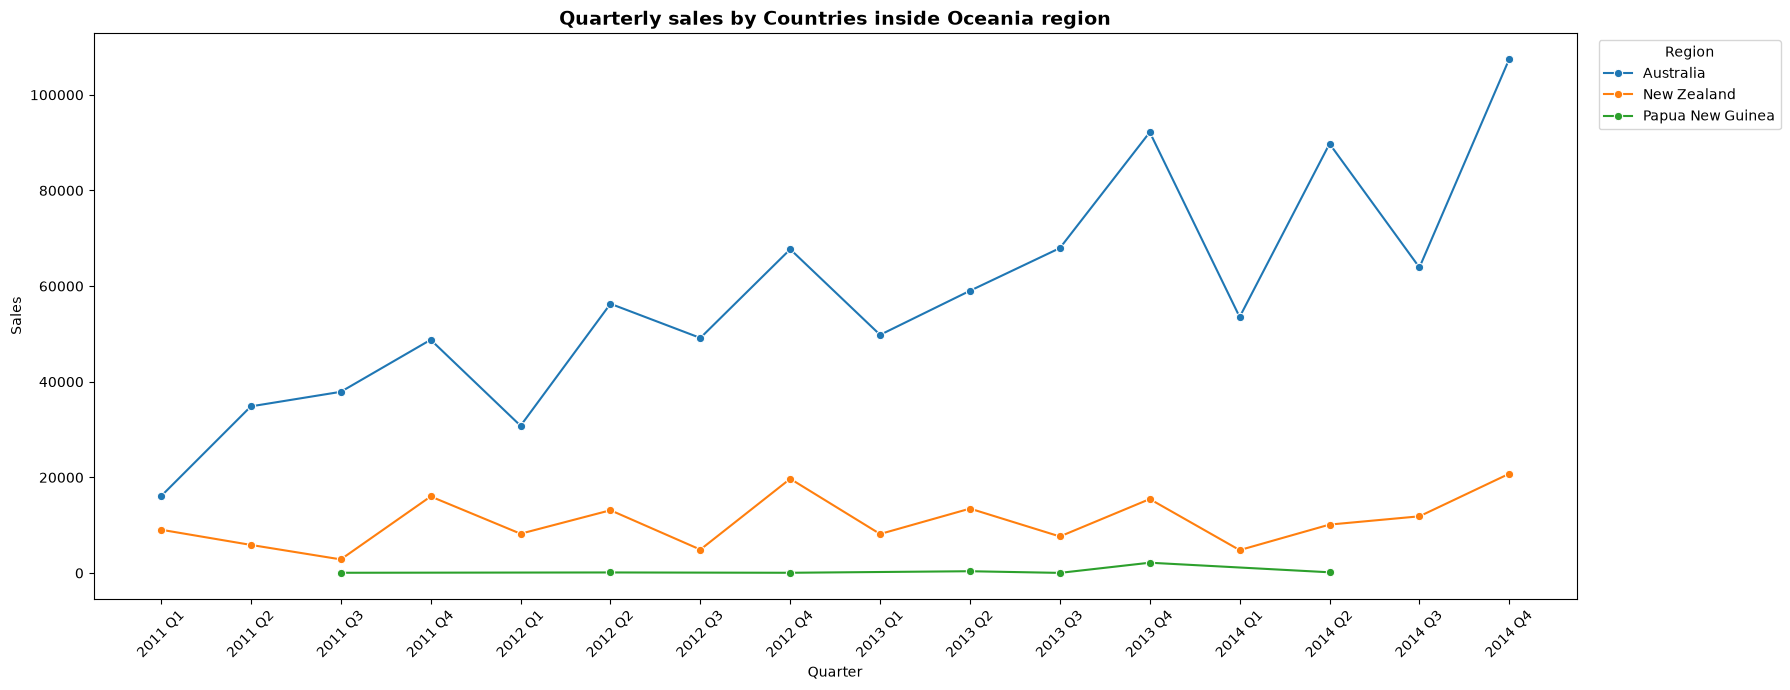

In [44]:
oceania_q=(
    df[df["region"]=="Oceania"].groupby(["year","quarter","country"], as_index=False)["sales"]
    .sum().sort_values(["year","quarter"])
)
oceania_q["period"]=oceania_q["year"].astype(str)+" "+"Q"+oceania_q["quarter"].astype(str)

plt.figure(figsize=(18, 7))
sns.lineplot(data=oceania_q, x="period", y="sales",hue="country", marker="o")
plt.title("Quarterly sales by Countries inside Oceania region", fontsize=14, fontweight="bold")
plt.xlabel("Quarter")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.legend(title="Region", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

Comparing to both **region** and **countries**
 APAC Oceania region **Australia** is the strongest quarterly performer in the top-two data, and top-two sales grew every year from 2011 to 2014.

In [45]:
best_country_q = (
    df.groupby(["year", "quarter", "country"])["sales"].sum()
    .reset_index()
    .sort_values(["year", "quarter", "sales"], ascending=[True, True, False])
    .groupby(["year", "quarter"]).head(1)
)
best_country_q


,year,quarter,country,sales
87,2011,1,United States,74445.0
183,2011,2,United States,86540.0
274,2011,3,United States,143643.0
384,2011,4,United States,179627.0
475,2012,1,United States,68858.0
577,2012,2,United States,89135.0
682,2012,3,United States,130265.0
786,2012,4,United States,182302.0
884,2013,1,United States,92602.0
994,2013,2,United States,135390.0


But when we compare only with Country **UNITED STATES** have the most highest sales because among the regions united states are in multiple region

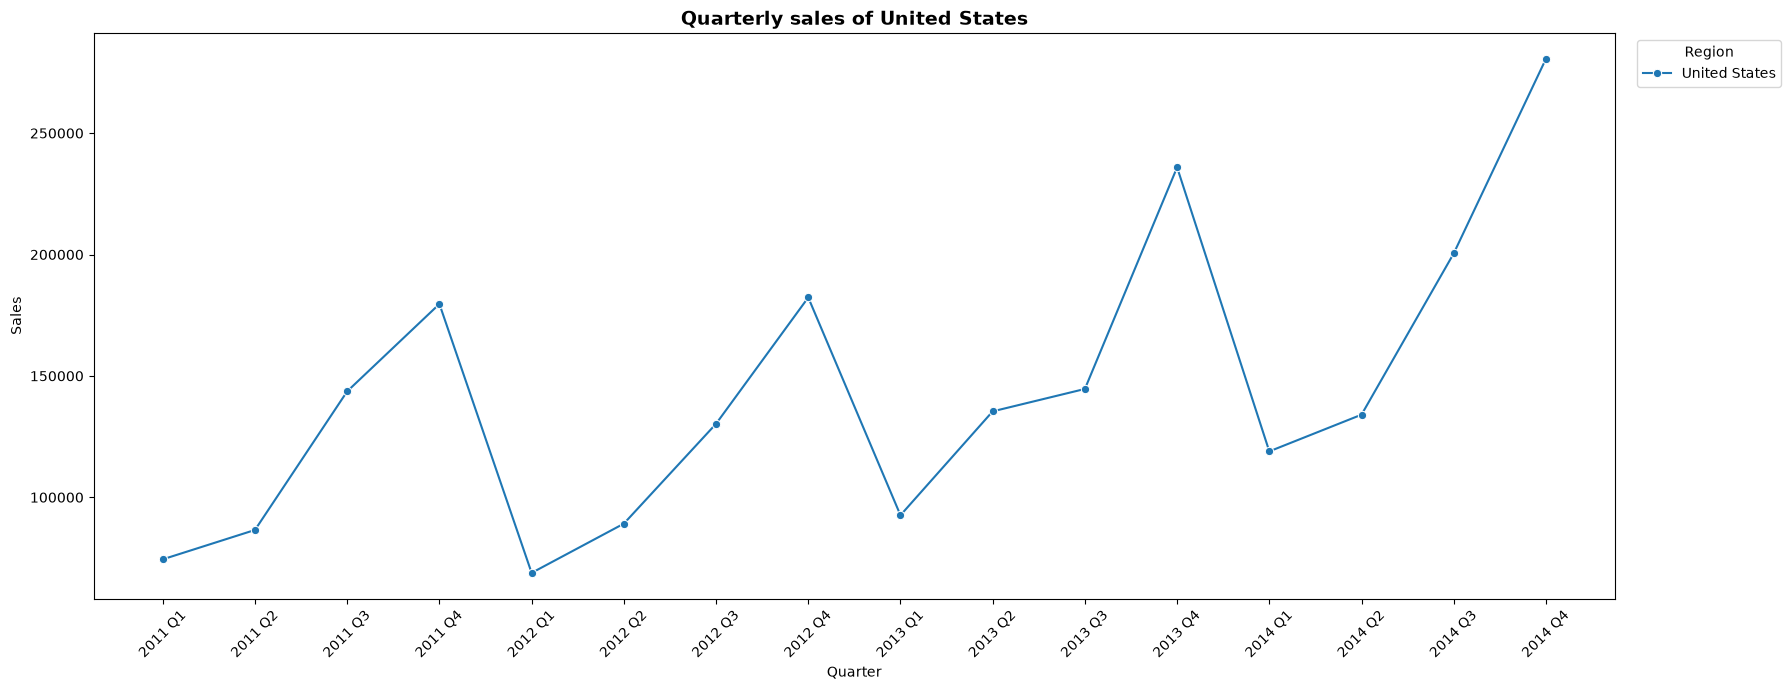

In [46]:

country = best_country_q
country["period"] = country["year"].astype(str) + " Q" + country["quarter"].astype(str)

plt.figure(figsize=(18, 7))
sns.lineplot(data=country, x="period", y="sales", hue="country", marker="o")
plt.title("Quarterly sales of United States", fontsize=14, fontweight="bold")
plt.xlabel("Quarter")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.legend(title="Region", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

But when we only check the country based top sales on quarter top is **USA**

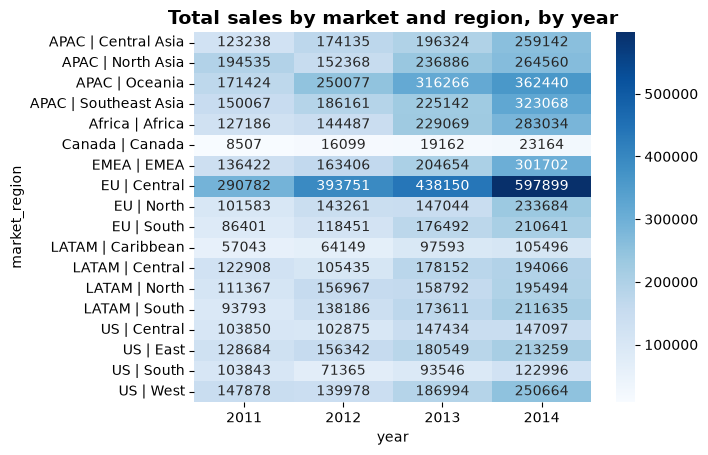

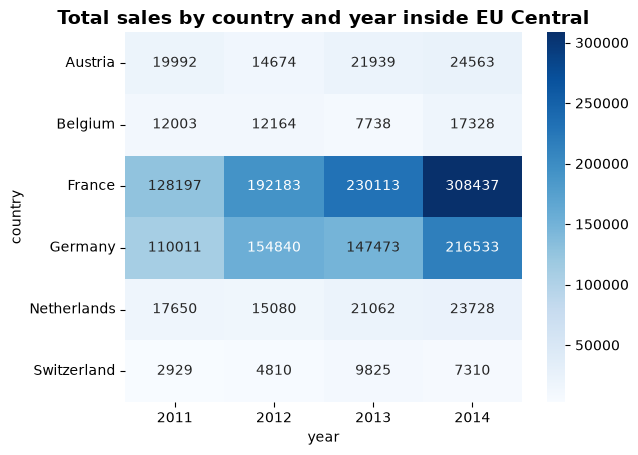

In [47]:
sns.heatmap(df.pivot_table(index="market_region", columns="year", values="sales", aggfunc="sum"),
            annot=True, fmt=".0f", cmap="Blues")
plt.title("Total sales by market and region, by year", fontsize=14, fontweight="bold")
plt.show()

eu_central = df[df["market_region"] == "EU | Central"].pivot_table(
    index="country", columns="year", values="sales", aggfunc="sum")
sns.heatmap(eu_central, annot=True, fmt=".0f", cmap="Blues")
plt.title("Total sales by country and year inside EU Central", fontsize=14, fontweight="bold")
plt.show()

### * Over past 4 years **EU Central** regions performs best on **2014**<br>
### * On Central region **France** out performs every country in all 4 years.

In [48]:
region_wise =(
    df.groupby(["market","region"])
    .agg(
        sales=("sales","sum"),
        profit=("profit","sum"),
        avg_discount=("discount","mean"),
        orders=("order_id","nunique")
    )
)
region_wise["profit_margin_pct"]=(
    region_wise["profit"]/region_wise["sales"]*100
).round(2)

region_wise["avg_discount_pct"]= (region_wise["avg_discount"]*100).round(2)
region_wise = region_wise.drop(columns ="avg_discount").sort_values("profit_margin_pct",ascending= False)
region_wise

sales     profit  orders  profit_margin_pct  \
market region                                                            
Canada Canada            66932.0   17817.39     201              26.62   
APAC   North Asia       848349.0  165578.35    1150              19.52   
       Central Asia     752839.0  132480.18    1026              17.60   
LATAM  North            622620.0  102818.26    1329              16.51   
US     West             725514.0  108418.31    1611              14.94   
EU     North            625572.0   91779.82    1027              14.67   
US     East             678834.0   91522.50    1401              13.48   
EU     Central         1720582.0  215533.96    2576              12.53   
US     South            391750.0   46749.49     822              11.93   
Africa Africa           783776.0   88871.49    2232              11.34   
EU     South            591985.0   65515.79     995              11.07   
APAC   Oceania         1100207.0  120088.89    1744              10.92   
LATAM  Caribbean        324281.0   34571.34     855              10.66   
       Central          600561.0   56163.55    1504               9.35   
US     Central          501256.0   39707.35    1175               7.92   
EMEA   EMEA             806184.0   43897.99    2462               5.45   
LATAM  South            617225.0   28090.48    1456               4.55   
APAC   Southeast Asia   884438.0   17852.49    1517               2.02   

                       avg_discount_pct  
market region                            
Canada Canada                      0.00  
APAC   North Asia                  4.87  
       Central Asia                6.75  
LATAM  North                       6.15  
US     West                       10.93  
EU     North                      13.86  
US     East                       14.54  
EU     Central                     9.13  
US     South                      14.73  
Africa Africa                     15.67  
EU     South                       9.95  
APAC   Oceania                    15.32  
LATAM  Caribbean                  13.56  
       Central                    15.25  
US     Central                    24.01  
EMEA   EMEA                       19.61  
LATAM  South                      18.37  
APAC   Southeast Asia             27.21

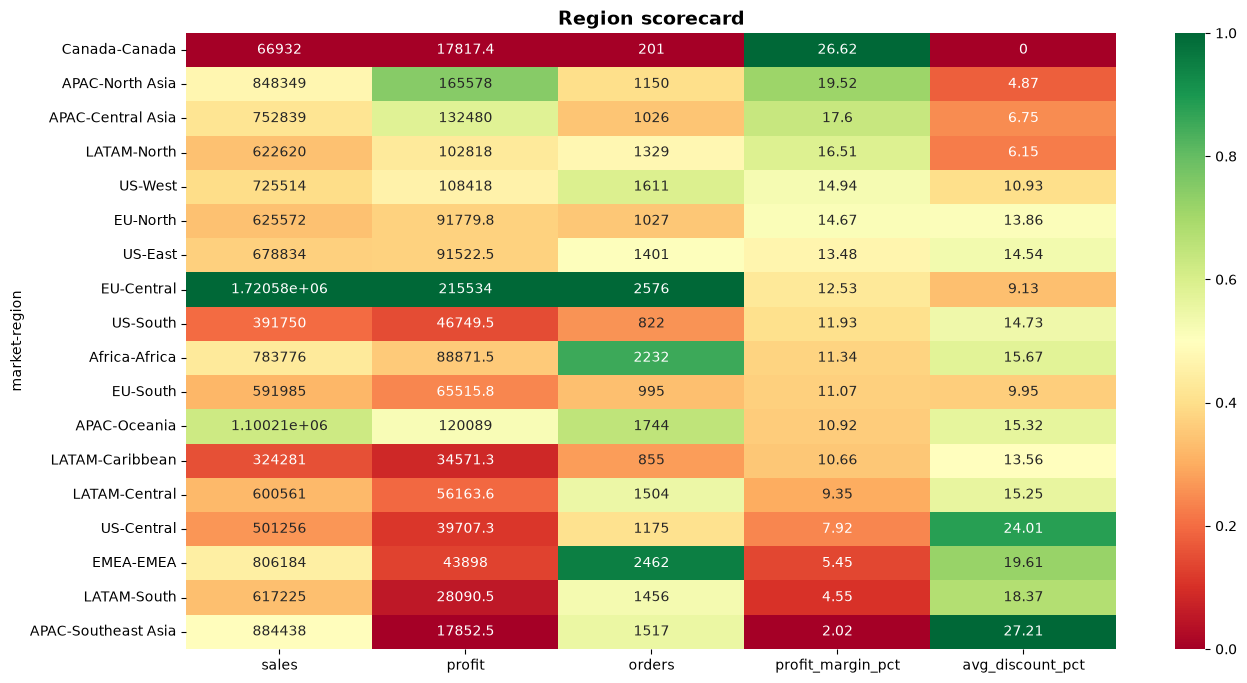

In [49]:
data = region_wise[["sales", "profit", "orders", "profit_margin_pct", "avg_discount_pct"]]

plt.figure(figsize=(15,8))
sns.heatmap((data - data.min()) / (data.max() - data.min()), annot=data.round(2), fmt="g", cmap="RdYlGn")
plt.title("Region scorecard",fontsize=14,fontweight="bold")
plt.show()

* Canada has the highest profit margin **(26.62)**, but only have a small volume<br>
* APAC North Asia have the second highest margin **(19.52)**, and only **(4.87)** average discount% on 848k sales<br>
* EU Central have highest sales of **(1.7M)**, profit of **(215533.96)**, but margin is **(12)** so the * volume speaks the sales
* Southeast Asia is the problem. Brings out $884438 sales but very little amout of profit **(2.02%)**


What happened in Southeast Asia region?

In [50]:
SEAsia=(
    df.loc[(df["market"]=="APAC") & (df["region"]=="Southeast Asia")]
    .groupby(["market","region","country"])
    .agg(
        sales=("sales","sum"),
        profit=("profit","sum"),
        avg_discount=("discount","mean"),
        orders=("order_id","nunique"),
    )
)
SEAsia["margin_pct"]=(SEAsia["profit"]/SEAsia["sales"]*100).round(2)
SEAsia["avg_discout_pct"]=(SEAsia["avg_discount"]*100).round(2)
SEAsia=SEAsia.drop(columns="avg_discount").sort_values("profit")

SEAsia

sales    profit  orders  margin_pct  \
market region         country                                                   
APAC   Southeast Asia Philippines      183433.0 -16128.20     326       -8.79   
                      Thailand          77048.0  -7308.17     138       -9.49   
                      Myanmar (Burma)   34144.0  -2109.26      58       -6.18   
                      Vietnam           65802.0  -1870.21     122       -2.84   
                      Cambodia          17476.0   4476.54      21       25.62   
                      Singapore         40285.0   8853.06      72       21.98   
                      Indonesia        404887.0  15608.77     698        3.86   
                      Malaysia          61363.0  16329.96      82       26.61   

                                       avg_discout_pct  
market region         country                           
APAC   Southeast Asia Philippines                34.59  
                      Thailand                   36.25  
                      Myanmar (Burma)            23.62  
                      Vietnam                    23.94  
                      Cambodia                    0.00  
                      Singapore                   0.00  
                      Indonesia                  29.73  
                      Malaysia                    0.00

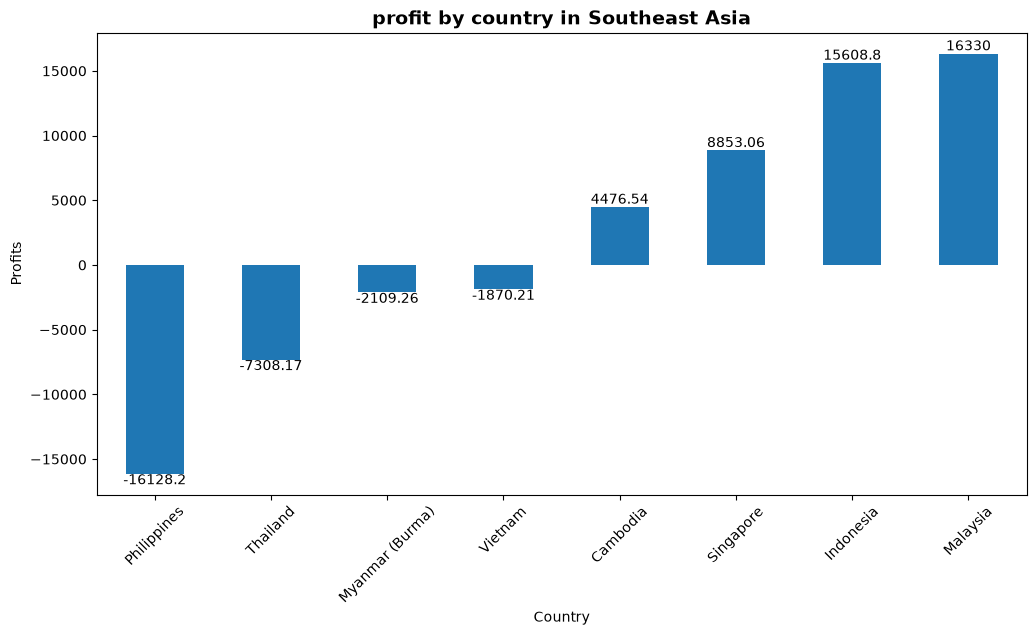

In [51]:
sea=df.loc[(df["market"]=="APAC")&(df["region"]=="Southeast Asia")]
profit_by_country=sea.groupby("country")["profit"].sum().sort_values()

ax=profit_by_country.plot(kind="bar",color="tab:blue",figsize=(12,6))
ax.bar_label(ax.containers[0])
plt.title("profit by country in Southeast Asia",fontsize=14,fontweight="bold")
plt.ylabel("Profits")
plt.xticks(rotation=45)
plt.xlabel("Country")
plt.show()

We found that **Philippines**,**Thailand** and **Myanmar** are the lossing market and highest average discount<br><br><br>
We can see **Indonesia** have the highest sales (404887.0) and largest orders (698) having **(3.86%)** of profit

In [52]:
SEAsia_loss= df.loc[(df["market"]=="APAC")&(df["region"]=="Southeast Asia")]

cat=(
    SEAsia_loss.groupby(["country","sub_category"])
    .agg(sales=("sales","sum"),profit=("profit","sum"),orders=("order_id","nunique"))
)
cat["margin_pct"]=(cat["profit"]/cat["sales"]*100).round(2)
cat_neg=cat.loc[["Philippines","Thailand","Myanmar (Burma)"]].sort_values("margin_pct")
cat_neg=cat_neg.loc[cat_neg["margin_pct"]<0].sort_values("margin_pct").reset_index()
cat_neg.head(10)

,country,sub_category,sales,profit,orders,margin_pct
0,Thailand,Tables,3822.0,-3187.90,4,-83.41
1,Myanmar (Burma),Tables,2096.0,-1602.79,4,-76.47
2,Thailand,Envelopes,668.0,-338.08,11,-50.61
3,Philippines,Tables,6308.0,-3150.68,10,-49.95
4,Philippines,Supplies,3513.0,-1714.19,39,-48.80
5,Thailand,Supplies,1386.0,-671.40,21,-48.44
6,Thailand,Fasteners,361.0,-167.14,14,-46.30
7,Thailand,Paper,829.0,-357.89,16,-43.17
8,Philippines,Paper,1853.0,-746.99,34,-40.31
9,Philippines,Storage,7404.0,-2982.48,35,-40.28


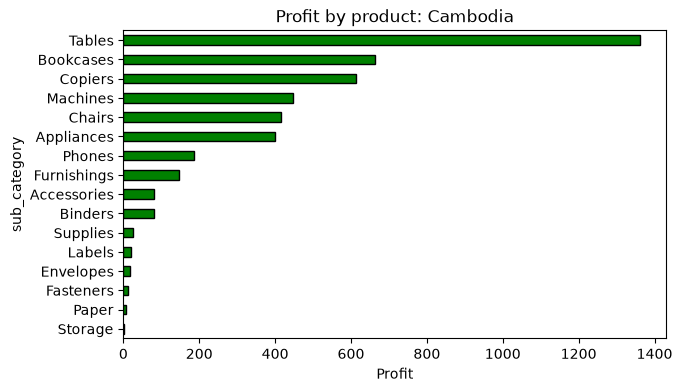

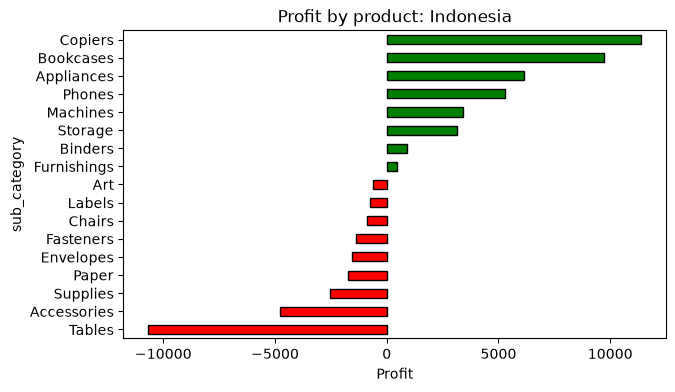

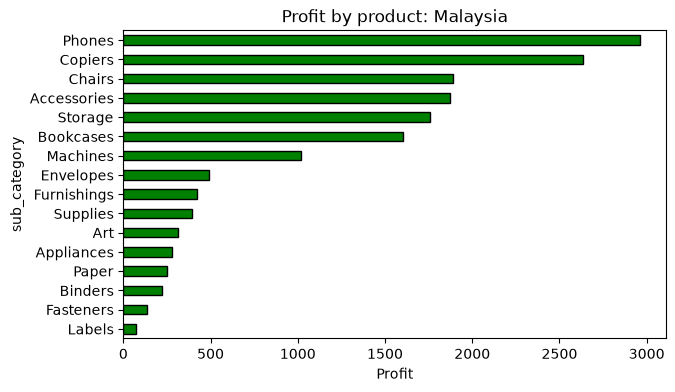

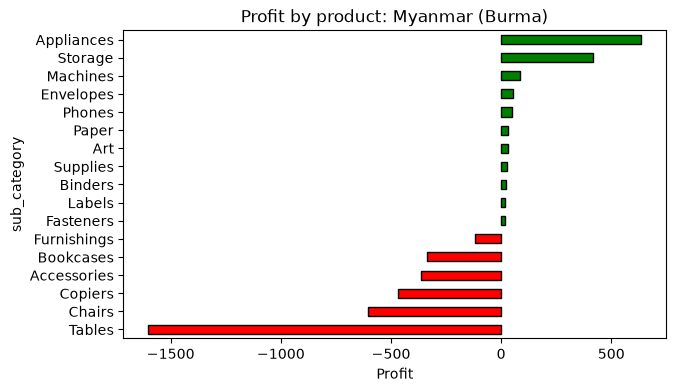

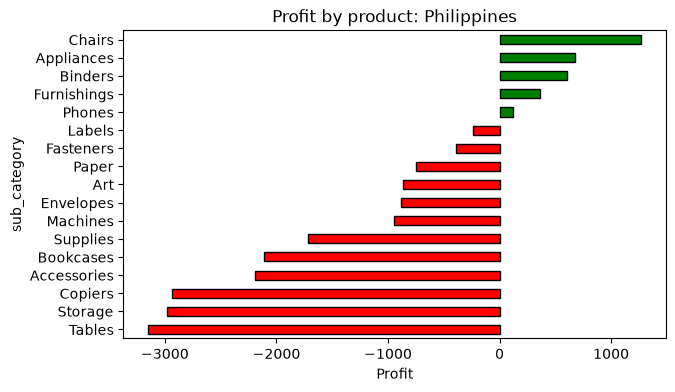

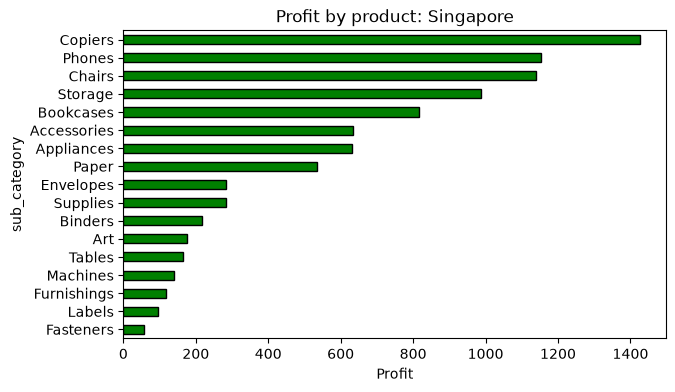

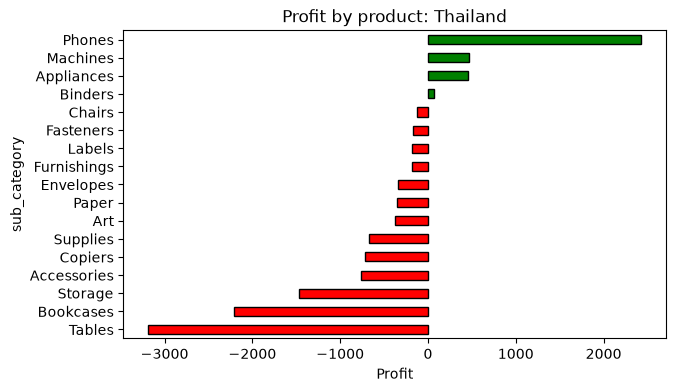

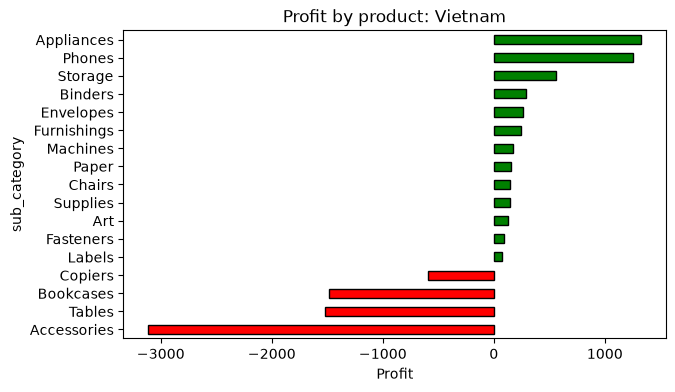

In [53]:
for country, grp in sea.groupby("country"):
    s = grp.groupby("sub_category")["profit"].sum().sort_values()
    plt.figure(figsize=(7, 4))
    s.plot(kind="barh", color=["red" if v < 0 else "green" for v in s], edgecolor="black")
    plt.title(f"Profit by product: {country}")
    plt.xlabel("Profit")
    plt.show()

* **Tables** are the major product problem that appears in all 3 countires loses of **7.9k** on **12.2k sales** a margin of **-65%** <br>
* **Thailand** is most loss making rows of **4.7k loss** and **7.1k sales** 

*  **Philippines** has the largest money loss in  4 rows total of **8.6k** loss on **19.1k** of sales    **-45%**

### We found that these are the products which causing loss in Southeast Asia.

#### Southeast Asia’s margin (2.0%) is well below the company average. Four countries account for about 27k in losses, and loss-making countries carry deeper discounts than profitable ones.

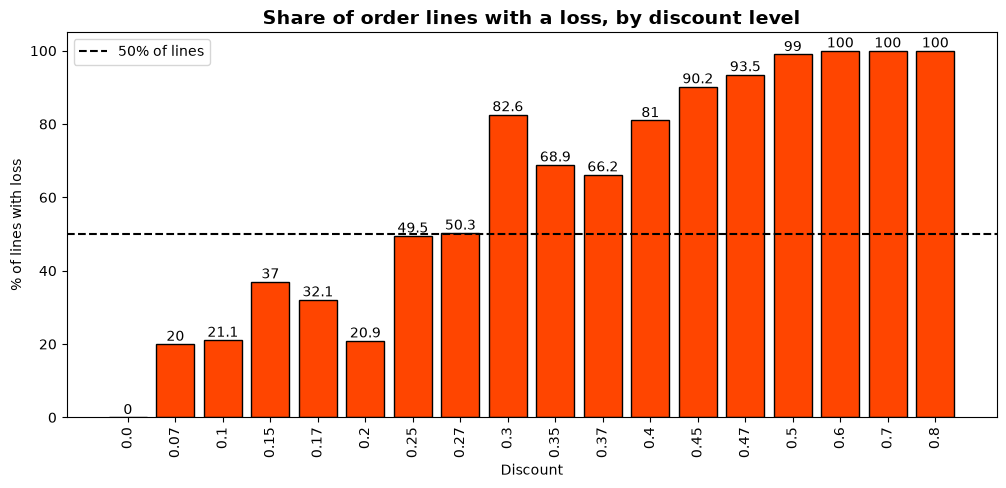

In [66]:
plt.figure(figsize=(12, 5))
bars = plt.bar(reliable.index.astype(str), reliable["loss_share_pct"],
               color="orangered", edgecolor="black")
plt.bar_label(bars)
plt.axhline(50, color="black", linestyle="--", label="50% of lines")
plt.title("Share of order lines with a loss, by discount level", fontsize=14, fontweight="bold")
plt.xlabel("Discount")
plt.ylabel("% of lines with loss")
plt.xticks(rotation=90)
plt.legend()
plt.show()

In [55]:
loss = df[df["profit"] < 0]
share = loss.loc[loss["discount"] > 0.20, "profit"].sum() / loss["profit"].sum() * 100
print(f"{share:.1f}% of total loss comes from lines with discount above 20%")

92.0% of total loss comes from lines with discount above 20%


### Discounts are linked to losses. Order lines with discounts above 20% account for 92.2% of total loss value. Discount levels with fewer than 30 order lines were excluded, because their loss share can be misleading.

                        sales    profit  margin_pct
market sub_category                                
EU     Tables        105380.0 -20998.44      -19.93
APAC   Tables        225096.0 -20128.73       -8.94
US     Tables        206968.0 -17725.57       -8.56
LATAM  Tables        144878.0 -12305.87       -8.49
US     Bookcases     114879.0  -3472.59       -3.02
       Supplies       46679.0  -1189.08       -2.55
EMEA   Chairs         69821.0   -609.59       -0.87
LATAM  Furnishings    62463.0    234.84        0.38
US     Machines      189243.0   3384.72        1.79
EMEA   Phones        114521.0   2990.94        2.61


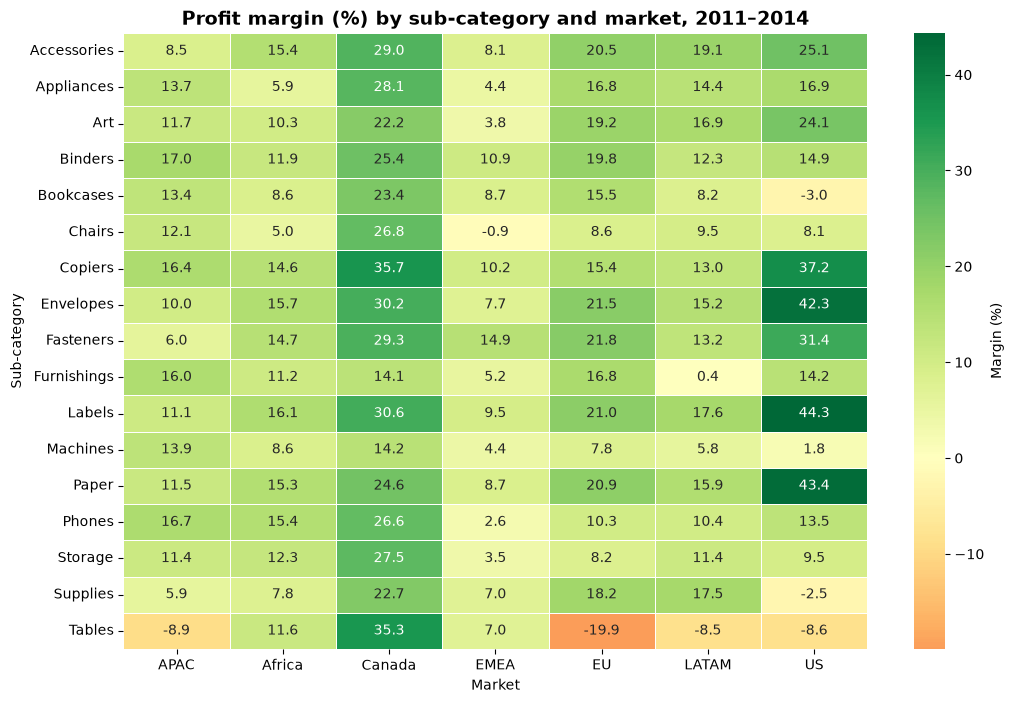

In [61]:
sub_mkt = (df.groupby(["market", "sub_category"])
             .agg(sales=("sales", "sum"), profit=("profit", "sum")))
sub_mkt["margin_pct"] = (sub_mkt["profit"] / sub_mkt["sales"] * 100).round(2)
print(sub_mkt.sort_values("margin_pct").head(10))   # weakest combinations

margin_matrix = sub_mkt["margin_pct"].unstack("market")

plt.figure(figsize=(12, 8))
sns.heatmap(margin_matrix, annot=True, fmt=".1f", cmap="RdYlGn", center=0,
            linewidths=0.5, cbar_kws={"label": "Margin (%)"})
plt.title("Profit margin (%) by sub-category and market, 2011–2014",
          fontsize=14, fontweight="bold")
plt.xlabel("Market")
plt.ylabel("Sub-category")
plt.show()

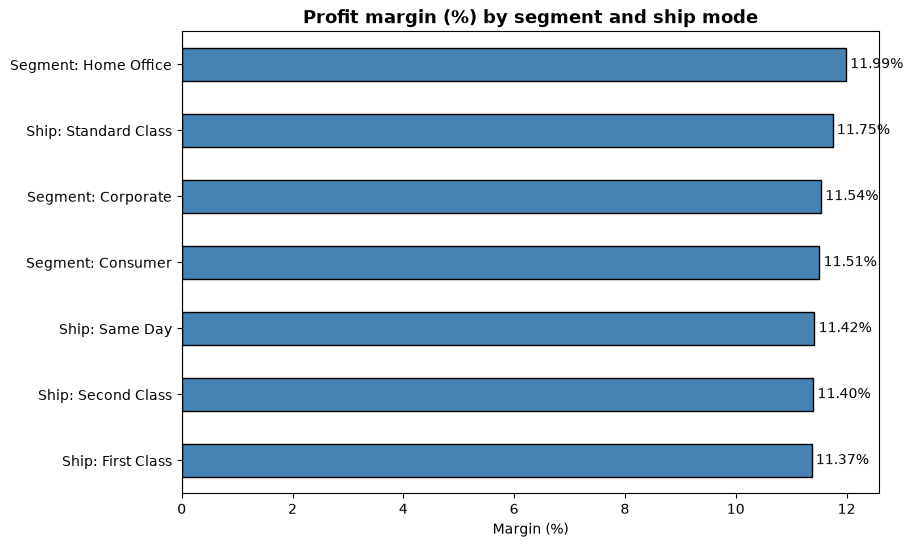

In [68]:
t = pd.concat([
    df.groupby("segment").agg(sales=("sales", "sum"), profit=("profit", "sum")).rename(index=lambda x: f"Segment: {x}"),
    df.groupby("ship_mode").agg(sales=("sales", "sum"), profit=("profit", "sum")).rename(index=lambda x: f"Ship: {x}"),
])
t["margin_pct"] = (t["profit"] / t["sales"] * 100).round(2)

ax = t["margin_pct"].sort_values().plot(kind="barh", color="steelblue",
                                        edgecolor="black", figsize=(9, 6))
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=3)
plt.title("Profit margin (%) by segment and ship mode", fontsize=13, fontweight="bold")
plt.xlabel("Margin (%)")
plt.axvline(0, color="black", linewidth=0.8)
plt.show()

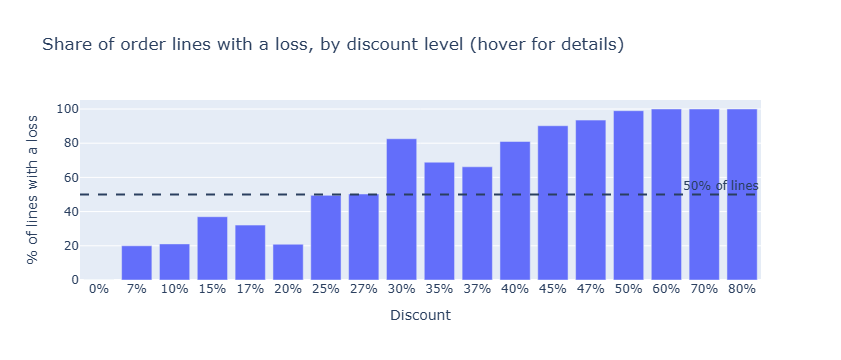

In [56]:
disc = (df.groupby("discount")
          .agg(lines=("row_id", "count"),
               loss_lines=("profit", lambda s: (s < 0).sum()),
               sales=("sales", "sum"),
               profit=("profit", "sum"))
          .reset_index())
disc = disc[disc["lines"] >= 30].copy()
disc["loss_share_pct"] = (disc["loss_lines"] / disc["lines"] * 100).round(1)
disc["margin_pct"] = (disc["profit"] / disc["sales"] * 100).round(1)
disc["discount_label"] = (disc["discount"] * 100).round(0).astype(int).astype(str) + "%"

fig = px.bar(
    disc, x="discount_label", y="loss_share_pct",
    hover_data={"lines": True, "sales": ":,.0f", "profit": ":,.0f",
                "margin_pct": True, "discount_label": False},
    labels={"discount_label": "Discount", "loss_share_pct": "% of lines with a loss"},
    title="Share of order lines with a loss, by discount level (hover for details)",
)
fig.add_hline(y=50, line_dash="dash", annotation_text="50% of lines")
fig.update_xaxes(type="category")
fig.show()

### Losses start to be the majority at a 30% discount.
* Up to 20% discount: most sales don’t lose money.
* From 30% to 80% discount: more than half lose money.

# Superstore Sales Profitability Analysis: Summary of Findings

**Period:** 1 January 2011 to 31 December 2014
**Data:** 51,290 order lines (one row per product within an order), 27 columns, no missing values, no duplicate rows
**Status:** Descriptive analysis. Covers sales, profit, margin, and discounts. Sub-category by market, segment and ship mode, and year-on-year margin are not covered in this submission.

---

## 1. Headline findings

- **Discounts are linked to losses.** Order lines with discounts above 20% account for **92.0%** of total loss value.
- **Losses are concentrated in a few places.** Four Southeast Asian countries (Philippines, Thailand, Myanmar, Vietnam) lose about **27.4k** combined.
- **Most of the business is profitable.** The United States, China, France, Germany, and Australia all make positive profit overall.
- **Margin varies widely by region.** Canada has the highest margin in the output (26.62%), but it's a small market.

---

## 2. Company-wide results

### Top countries by sales

| Country | Sales | Profit | Margin |
|---|---:|---:|---:|
| United States | 2,297,354 | 286,397.65 | 12.5% |
| Australia | 925,257 | 103,907.20 | 11.2% |
| France | 858,930 | 109,028.99 | 12.7% |
| China | 700,591 | 150,683.08 | 21.5% |
| Germany | 628,857 | 107,322.77 | 17.1% |

China has the highest margin of the top five by sales. The United States has the highest sales and profit in absolute terms.

### Countries with the largest losses

| Country | Total profit |
|---|---:|
| Turkey | −98,447.28 |
| Nigeria | −80,750.88 |
| Netherlands | −41,070.12 |
| Honduras | −29,482.32 |
| Pakistan | −22,446.63 |

### Top cities by sales

| City | Sales | Profit | Margin |
|---|---:|---:|---:|
| New York City | 256,397 | 62,036.93 | 24.2% |
| Los Angeles | 175,857 | 30,440.77 | 17.3% |
| Manila | 120,896 | −11,158.54 | −9.2% |
| Seattle | 119,552 | 29,156.08 | 24.4% |
| San Francisco | 112,690 | 17,507.32 | 15.5% |

Four of the top five cities by sales are in the United States. Manila is the only top-five city that loses money overall.

---

## 3. Regional margins

The highest-margin market regions in the output:

| Market | Region | Sales | Margin |
|---|---|---:|---:|
| Canada | Canada | 66,932 | 26.62% |
| APAC | North Asia | 848,349 | 19.52% |
| APAC | Central Asia | 752,839 | 17.60% |
| LATAM | North | 622,620 | 16.51% |
| US | West | 725,514 | 14.94% |
| EU | North | 625,572 | 14.67% |
| US | East | 678,834 | 13.48% |

**Note:** Regions are grouped by market and region together. Region names such as "Central" appear in several markets, so grouping by name alone would mix them.

---

## 4. Southeast Asia

Southeast Asia's margin is among the lowest of the large regions. Country-level results:

| Country | Sales | Profit | Margin |
|---|---:|---:|---:|
| Philippines | 183,433 | −16,128.20 | −8.79% |
| Thailand | 77,048 | −7,308.17 | −9.49% |
| Myanmar (Burma) | 34,144 | −2,109.26 | −6.18% |
| Vietnam | 65,802 | −1,870.21 | −2.84% |
| Cambodia | 17,476 | 4,476.54 | 25.62% |
| Singapore | 40,285 | 8,853.06 | 21.98% |

The four loss-making countries together lose about **27.4k**. Cambodia and Singapore are profitable.

### Where the losses come from

- **Tables** are the largest loss-maker in the region, with **−18,618.33** across all Southeast Asian countries.
- In the three countries with the clearest breakdown (Philippines, Thailand, Myanmar), Tables lose **7.9k** on **12.2k** of sales, a margin of about **−65%**.
- Specific product lines with the largest losses (margin in brackets):
  - Thailand, Tables: −3,187.90 (−83.4%)
  - Myanmar, Tables: −1,602.79 (−76.5%)
  - Philippines, Tables: −3,150.68 (−50.0%)
  - Philippines, Supplies: −1,714.19 (−48.8%)
- Other sub-categories with losses across the region: Accessories (−8,641.47), Supplies (−4,034.20), Paper (−1,859.00), Envelopes (−1,641.16), and Fasteners (−1,602.29).

---

## 5. Discounts and losses

- **Losses rise with discount.** The first discount level where most order lines lose money is about **20%**. Discount levels with fewer than 30 order lines were excluded, because their loss share can be misleading.
- **Most of the loss comes from deep discounts.** Order lines with discounts above 20% account for **92.2%** of total loss value.

**Important:** The exact threshold needs one more check. The discount values were not rounded when this was run, so 0.20 and 0.202 appear as separate levels. Re-run the analysis after rounding discounts to two decimal places, and use the threshold printed then.

---

## 6. Recommendations

1. **Cap discounts at 20% company-wide,** with lines above the cap requiring approval. The loss share starts to rise at about this level.
2. **Pilot the cap in Southeast Asia first,** since it has the lowest margins among the large regions and the largest losses.
3. **Review pricing for Tables** in Southeast Asia. Tables lose money in the countries with the clearest data, and the losses are large even at the sub-category level.

Before quoting any expected impact from these recommendations, run a simulation that caps discounts and recalculates margin. The data does not show how much volume would shift.

---

## 7. Limitations

- **No cost detail.** The dataset has no staff, rent, or overhead costs, so profit is before those costs.
- **Descriptive, not causal.** Discounts and losses occur together. The data does not prove that discounts cause the losses.
- **Order lines, not orders.** Counts of orders in this analysis use unique order IDs where stated. Other counts are order lines.
- **Unweighted average discounts.** Average discount is the mean across lines. Sales-weighted figures are used where margin is reported.
- **Zero-sales row removed.** One row with zero sales was removed.
- **No negative sales.** Returns appear to be unrecorded.
- **Scope.** Sub-category by market margin, segment and ship mode margin, and year-on-year margin change are not covered in this submission.

